# Evaluate Saved Models

This notebook evaluates the trained classifiers saved by `train_classifiers.ipynb`.

It does **not** retrain the models. It:

1. Loads labeled data
2. Applies the same preprocessing/features as `train_classifiers.ipynb`
3. Loads saved models with `joblib`
4. Runs predictions
5. Prints metrics
6. Shows confusion matrices and ROC curves


In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)


## 1. Load labeled data

In [2]:
LABELED_CSV_DIR = Path("../data/labeled_logs")

csv_files = sorted(LABELED_CSV_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {LABELED_CSV_DIR.resolve()}")

dfs = [pd.read_csv(file) for file in csv_files]
df = pd.concat(dfs, ignore_index=True)

print(f"Loaded {len(csv_files)} labeled CSV file(s)")
print(f"Total rows before cleaning: {len(df)}")
df.head()


Loaded 5 labeled CSV file(s)
Total rows before cleaning: 22026


,frame,track_id,class,dist,delta_dist,light_state,is_safe,is_oncoming
0,0,1,7,1.3,0.0,NaN,0,False
1,0,2,2,1.2,0.0,NaN,0,True
2,0,3,2,1.3,0.0,NaN,0,True
3,0,4,9,1.5,0.0,green,0,True
4,0,5,9,1.4,0.0,unknown,0,False


## 2. Apply same preprocessing/features as `train_classifiers.ipynb`

In [5]:
MODEL_DIR = Path("../models")
ENCODER_PATH = MODEL_DIR / "label_encoder.pkl"

if not ENCODER_PATH.exists():
    raise FileNotFoundError(
        f"Missing label encoder: {ENCODER_PATH}. Run train_classifiers.ipynb first."
    )

le = joblib.load(ENCODER_PATH)

# Match train_classifiers.ipynb cleaning steps
df = df[df["dist"].notna()].copy()
df = df[df["light_state"] != "unknown"].copy()

# Convert is_oncoming to numeric exactly like training
if "is_oncoming" not in df.columns:
    raise KeyError("Missing required column: is_oncoming")

df["is_oncoming"] = df["is_oncoming"].astype(int)

# Use the saved encoder from training instead of fitting a new one
known_light_states = set(le.classes_)
current_light_states = set(df["light_state"].unique())
unknown_states = current_light_states - known_light_states

# if unknown_states:
#     raise ValueError(
#         f"Found light_state values not seen during training: {unknown_states}. "
#         "Retrain the models or clean these rows before evaluation."
#     )

df["light_enc"] = le.transform(df["light_state"])

features = ["class", "dist", "delta_dist", "light_enc", "is_oncoming"]
target = "is_safe"

missing_columns = [col for col in features + [target] if col not in df.columns]
if missing_columns:
    raise KeyError(f"Missing required column(s): {missing_columns}")

X = df[features]
y = df[target].astype(int)

# Same split as train_classifiers.ipynb
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print(f"Rows after cleaning: {len(df)}")
print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")
print("Class distribution:")
print(y.value_counts())

X_test.head()


Rows after cleaning: 14905
Train size: 11924, Test size: 2981
Class distribution:
is_safe
0    9434
1    5471
Name: count, dtype: int64


,class,dist,delta_dist,light_enc,is_oncoming
10970,2,1.1,0.0,3,1
21608,2,1.1,0.0,3,0
8568,2,1.2,0.0,3,0
3466,7,1.1,0.0,3,0
8563,2,1.0,0.0,3,1


## 3. Load saved models with `joblib`

In [6]:
model_paths = {
    "Logistic Regression": MODEL_DIR / "logistic_regression.pkl",
    "Decision Tree": MODEL_DIR / "decision_tree.pkl",
    "Random Forest": MODEL_DIR / "random_forest.pkl",
}

missing_models = [str(path) for path in model_paths.values() if not path.exists()]
if missing_models:
    raise FileNotFoundError(
        "Missing model file(s):" + " ".join(missing_models) +
        "un train_classifiers.ipynb first to create the saved models."
    )

models = {name: joblib.load(path) for name, path in model_paths.items()}

print("Loaded models:")
for name, path in model_paths.items():
    print(f"- {name}: {path}")


Loaded models:
- Logistic Regression: ../models/logistic_regression.pkl
- Decision Tree: ../models/decision_tree.pkl
- Random Forest: ../models/random_forest.pkl


## 4-5. Run predictions and print metrics

In [8]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
    }

    if hasattr(model, "predict_proba") and len(set(y_test)) == 2:
        y_score = model.predict_proba(X_test)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y_test, y_score)
    else:
        row["ROC-AUC"] = None

    results.append(row)

    print(f"{'=' * 60}")
    print(name)
    print(f"{'=' * 60}")
    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(results).set_index("Model")
results_df


Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.62      0.73      1888
           1       0.57      0.88      0.69      1093

    accuracy                           0.71      2981
   macro avg       0.73      0.75      0.71      2981
weighted avg       0.78      0.71      0.72      2981

Decision Tree
              precision    recall  f1-score   support

           0       0.90      0.79      0.84      1888
           1       0.70      0.86      0.77      1093

    accuracy                           0.81      2981
   macro avg       0.80      0.82      0.81      2981
weighted avg       0.83      0.81      0.81      2981

Random Forest
              precision    recall  f1-score   support

           0       0.90      0.79      0.84      1888
           1       0.70      0.86      0.77      1093

    accuracy                           0.81      2981
   macro avg       0.80      0.82      0.81      2981
weighted avg       0.83   

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.712177,0.569816,0.877402,0.690922,0.829823
Decision Tree,0.811808,0.698804,0.855444,0.769231,0.912209
Random Forest,0.812814,0.700075,0.856359,0.770370,0.912049


## 6. Show confusion matrices

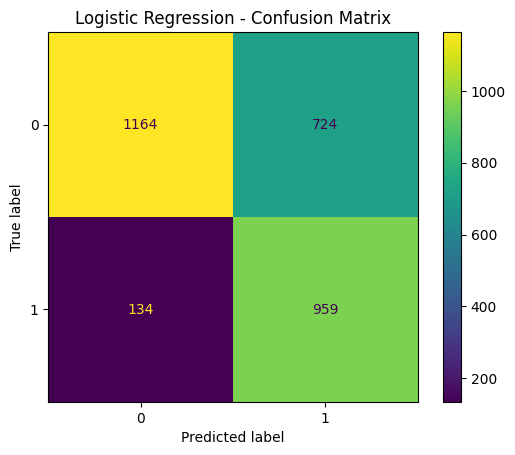

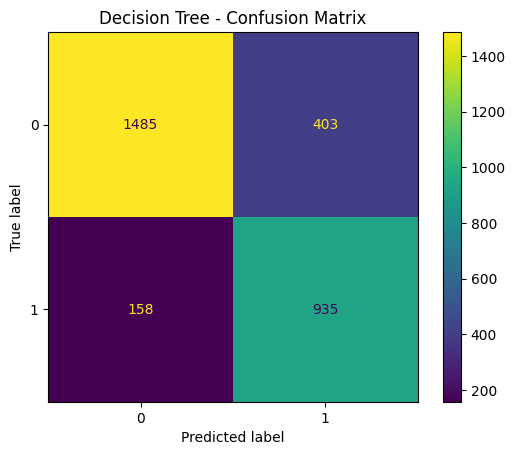

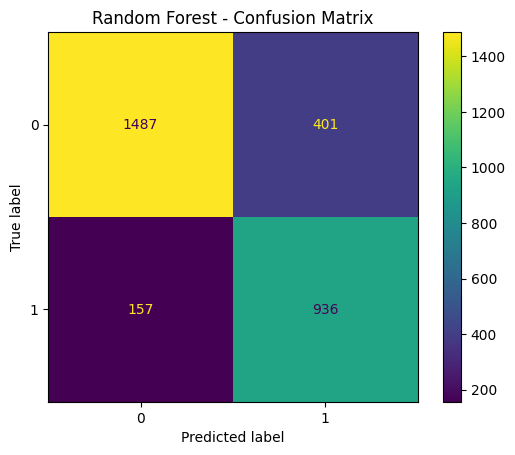

In [9]:
for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
    plt.title(f"{name} - Confusion Matrix")
    plt.show()


## 6. Show ROC curves

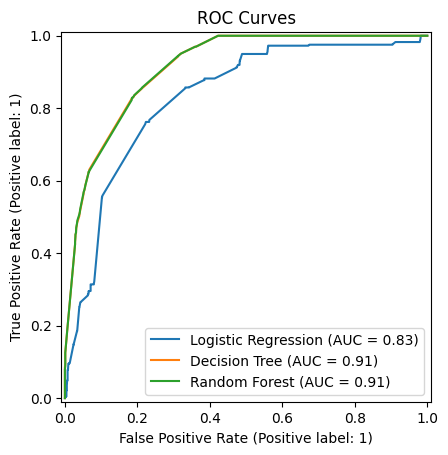

In [10]:
if len(set(y_test)) != 2:
    print("ROC curves require exactly 2 classes in y_test.")
else:
    ax = None

    for name, model in models.items():
        if hasattr(model, "predict_proba"):
            display = RocCurveDisplay.from_estimator(
                model,
                X_test,
                y_test,
                name=name,
                ax=ax,
            )
            ax = display.ax_
        else:
            print(f"Skipping {name}: model does not support predict_proba().")

    if ax is not None:
        ax.set_title("ROC Curves")
        plt.show()


## Optional: save metric summary

In [11]:
OUTPUT_DIR = Path("../data/evaluation_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "model_metrics.csv"
results_df.to_csv(output_path)

print(f"Saved metrics to: {output_path}")


Saved metrics to: ../data/evaluation_results/model_metrics.csv
